# DUOC UC
## Estadística Descriptiva

---

# Informe de análisis descriptivo
## Matrículas de educación superior en Arica y Parinacota
### Datos del año 2021

**Integrantes:** 
* Benjamín Cubillos
* Renato Troncoso
* Cristobal Pardo

**Docente:** Israel Barrera

**Sección:** 003D

**Fecha:** 11/11/2026

---

**Contenido del análisis**

Por completar

---

# Introducción

El presente análisis tiene como objetivo describir el conjunto de datos de matrículas de educación superior de Arica y Parinacota correspondiente a 2021. 


La **población de interés** corresponde a las matrículas de educación superior de la región de Arica y Parinacota durante 2021. La base analizada contiene **14.116 registros de matrícula**. Como se analizan todos los registros contenidos en el archivo regional disponible y no una selección de ellos, este conjunto se trata como un **registro censal de la población contenida en la base**, no como una muestra extraída mediante muestreo.

La unidad de análisis es cada registro de matrícula. Un registro no necesariamente representa a una persona única ni a una carrera única, por lo que las conclusiones se refieren a matrículas registradas. Los resultados describen este archivo y no se generalizan a otras regiones, otros años ni a información que no esté representada en la base.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

df = pd.read_excel("01_MATRICULAS_ED_SUPERIOR_ARICA_Y_PARINACOTA_2021.xlsx")

# Ítem 1

### Estudien la correlación entre el valor de la matrícula y el valor del arancel para toda la base de datos y luego separen por tipo de institución. ¿Los grupos se comportan parecido? ¿Vale la pena estudiar todos los grupos? Visualicen apropiadamente.

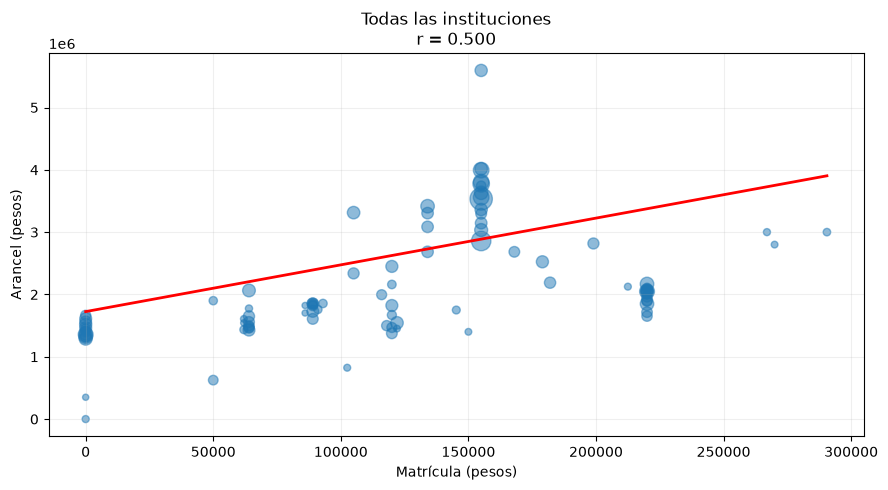

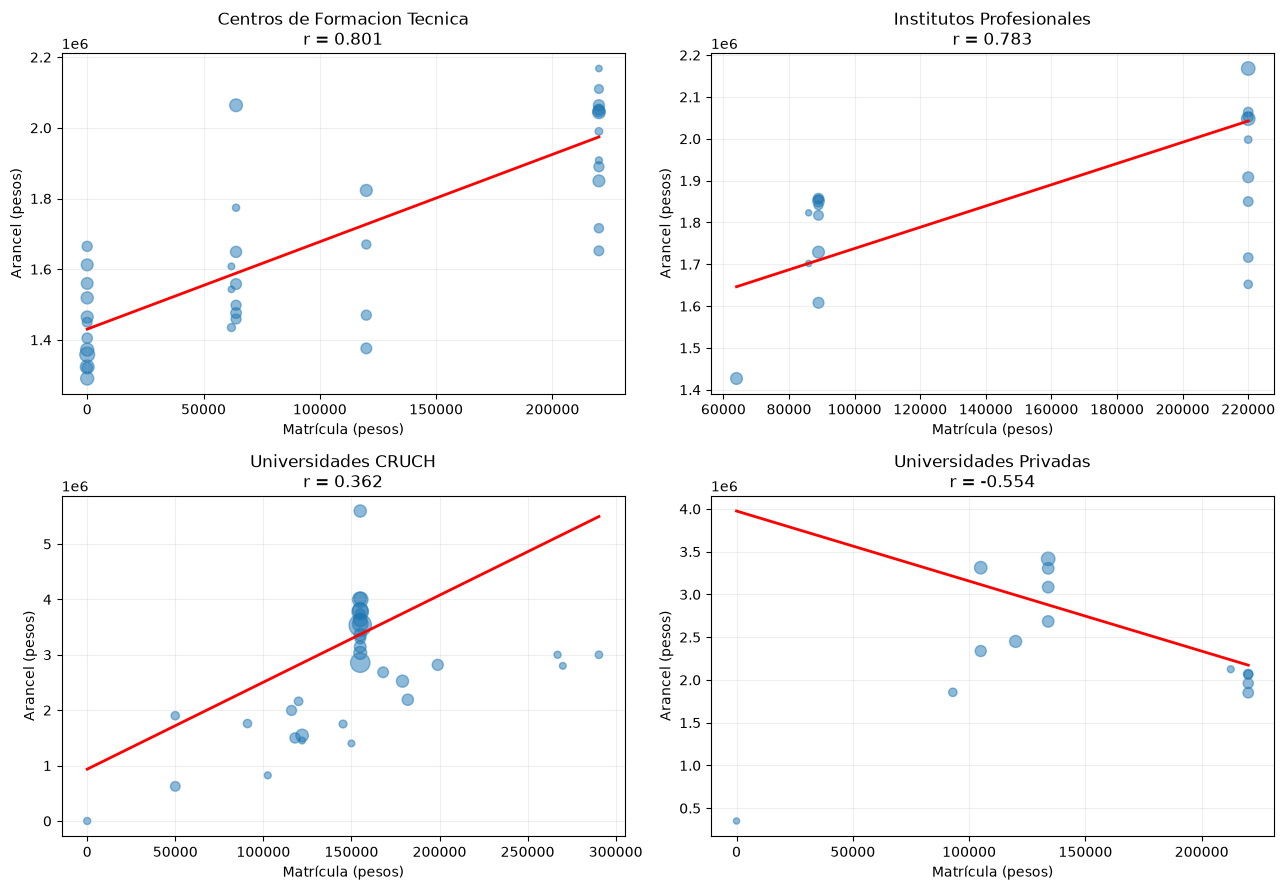

         Tipo de institución  Cantidad  Correlación
Centros de Formacion Tecnica      3594        0.801
    Institutos Profesionales      1430        0.783
         Universidades CRUCH      7849        0.362
      Universidades Privadas      1243       -0.554


In [5]:
x_col = "VALOR MATRICULA (PESOS)"
y_col = "VALOR ARANCEL (PESOS)"
grupo_col = "TIPO DE INSTITUCION"

# Preparar los datos
datos = df[[x_col, y_col, grupo_col]].copy()

for col in [x_col, y_col]:
    datos[col] = pd.to_numeric(datos[col], errors="coerce")

datos = datos.dropna()

# Función para graficar correlación y regresión
def graficar(ax, datos_grupo, titulo):
    x = datos_grupo[x_col].to_numpy()
    y = datos_grupo[y_col].to_numpy()

    r = np.corrcoef(x, y)[0, 1]

    # Agrupar valores repetidos para visualizar su frecuencia
    puntos = (
        datos_grupo.groupby([x_col, y_col])
        .size()
        .reset_index(name="frecuencia")
    )

    ax.scatter(
        puntos[x_col],
        puntos[y_col],
        s=15 + np.sqrt(puntos["frecuencia"]) * 5,
        alpha=0.5
    )

    # Regresión lineal
    modelo = LinearRegression()
    modelo.fit(x.reshape(-1, 1), y)

    linea_x = np.linspace(x.min(), x.max(), 100)
    linea_y = modelo.predict(linea_x.reshape(-1, 1))

    ax.plot(linea_x, linea_y, color="red", linewidth=2)

    ax.set_title(f"{titulo}\nr = {r:.3f}")
    ax.set_xlabel("Matrícula (pesos)")
    ax.set_ylabel("Arancel (pesos)")
    ax.grid(alpha=0.2)


# Gráfico general
fig, ax = plt.subplots(figsize=(9, 5))
graficar(ax, datos, "Todas las instituciones")
plt.tight_layout()
plt.show()


# Gráficos por tipo de institución
grupos = datos[grupo_col].unique()

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, grupo in zip(axes.flat, grupos):
    subset = datos[datos[grupo_col] == grupo]
    graficar(ax, subset, grupo)

plt.tight_layout()
plt.show()


# Tabla comparativa de correlaciones
resultados = []

for grupo, subset in datos.groupby(grupo_col):
    resultados.append({
        "Tipo de institución": grupo,
        "Cantidad": len(subset),
        "Correlación": subset[x_col].corr(subset[y_col])
    })

tabla = pd.DataFrame(resultados)
print(tabla.round(3).to_string(index=False))

Al analizar toda la base de datos, se obtuvo una correlación de Pearson de 0,500, lo que indica una relación positiva moderada entre el valor de la matrícula y el arancel.

Al separar los datos por tipo de institución, se observaron diferencias. Los Centros de Formación Técnica (0,801) y los Institutos Profesionales (0,783) presentan correlaciones positivas fuertes y similares. En cambio, las Universidades CRUCH (0,362) muestran una relación positiva más débil, mientras que las Universidades Privadas (-0,554) presentan una relación negativa moderada.

Conclusión: No todos los grupos se comportan de manera parecida. Se podrían estudiar conjuntamente los CFT y los IP por la similitud de sus correlaciones, pero conviene mantener separados los grupos universitarios, ya que presentan tendencias diferentes. Además, una correlación similar no garantiza que los valores o las pendientes sean iguales.

### ¿Cuál es la relación entre el arancel y la duración de la carrera correspondiente? ¿Es verdad que, mientras más larga la carrera, más cara? ¿Será igual en todas las áreas del conocimiento?

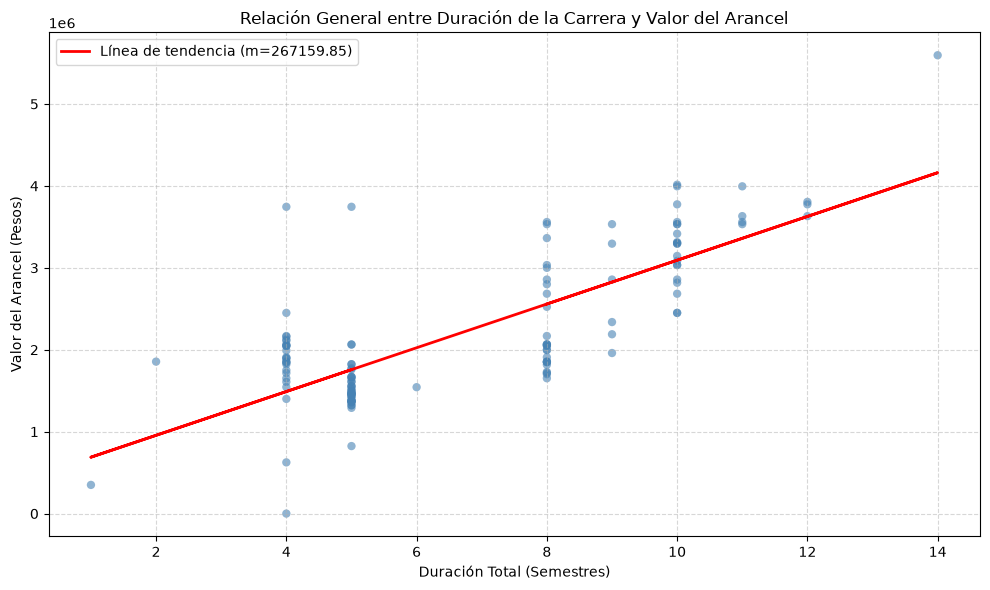

La correlación general de Pearson entre duración y arancel es: 0.77


In [7]:
columns_carrera = [
    'NOMBRE DE INSTITUCION',
    'NIVEL CARRERA',
    'AREA CONOCIMIENTO',
    'DURACION TOTAL CARRERA (SEMESTRES)',
    'VALOR ARANCEL (PESOS)'
]
carreras_unicas = df[columns_carrera].drop_duplicates().dropna()

carreras_unicas['DURACION TOTAL CARRERA (SEMESTRES)'] = pd.to_numeric(carreras_unicas['DURACION TOTAL CARRERA (SEMESTRES)'])
carreras_unicas['VALOR ARANCEL (PESOS)'] = pd.to_numeric(carreras_unicas['VALOR ARANCEL (PESOS)'])

# 1. Gráfico de dispersión general con línea de tendencia (solo con matplotlib)
plt.figure(figsize=(10, 6))
x = carreras_unicas['DURACION TOTAL CARRERA (SEMESTRES)']
y = carreras_unicas['VALOR ARANCEL (PESOS)']

plt.scatter(x, y, alpha=0.6, color='steelblue', edgecolor='none')

# Calcular línea de regresión
m, b = np.polyfit(x, y, 1)
plt.plot(x, m*x + b, color='red', linewidth=2, label=f'Línea de tendencia (m={m:.2f})')

plt.title('Relación General entre Duración de la Carrera y Valor del Arancel')
plt.xlabel('Duración Total (Semestres)')
plt.ylabel('Valor del Arancel (Pesos)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Calcular la correlación de Pearson general
corr_general = carreras_unicas['DURACION TOTAL CARRERA (SEMESTRES)'].corr(carreras_unicas['VALOR ARANCEL (PESOS)'])
print(f"La correlación general de Pearson entre duración y arancel es: {corr_general:.2f}")

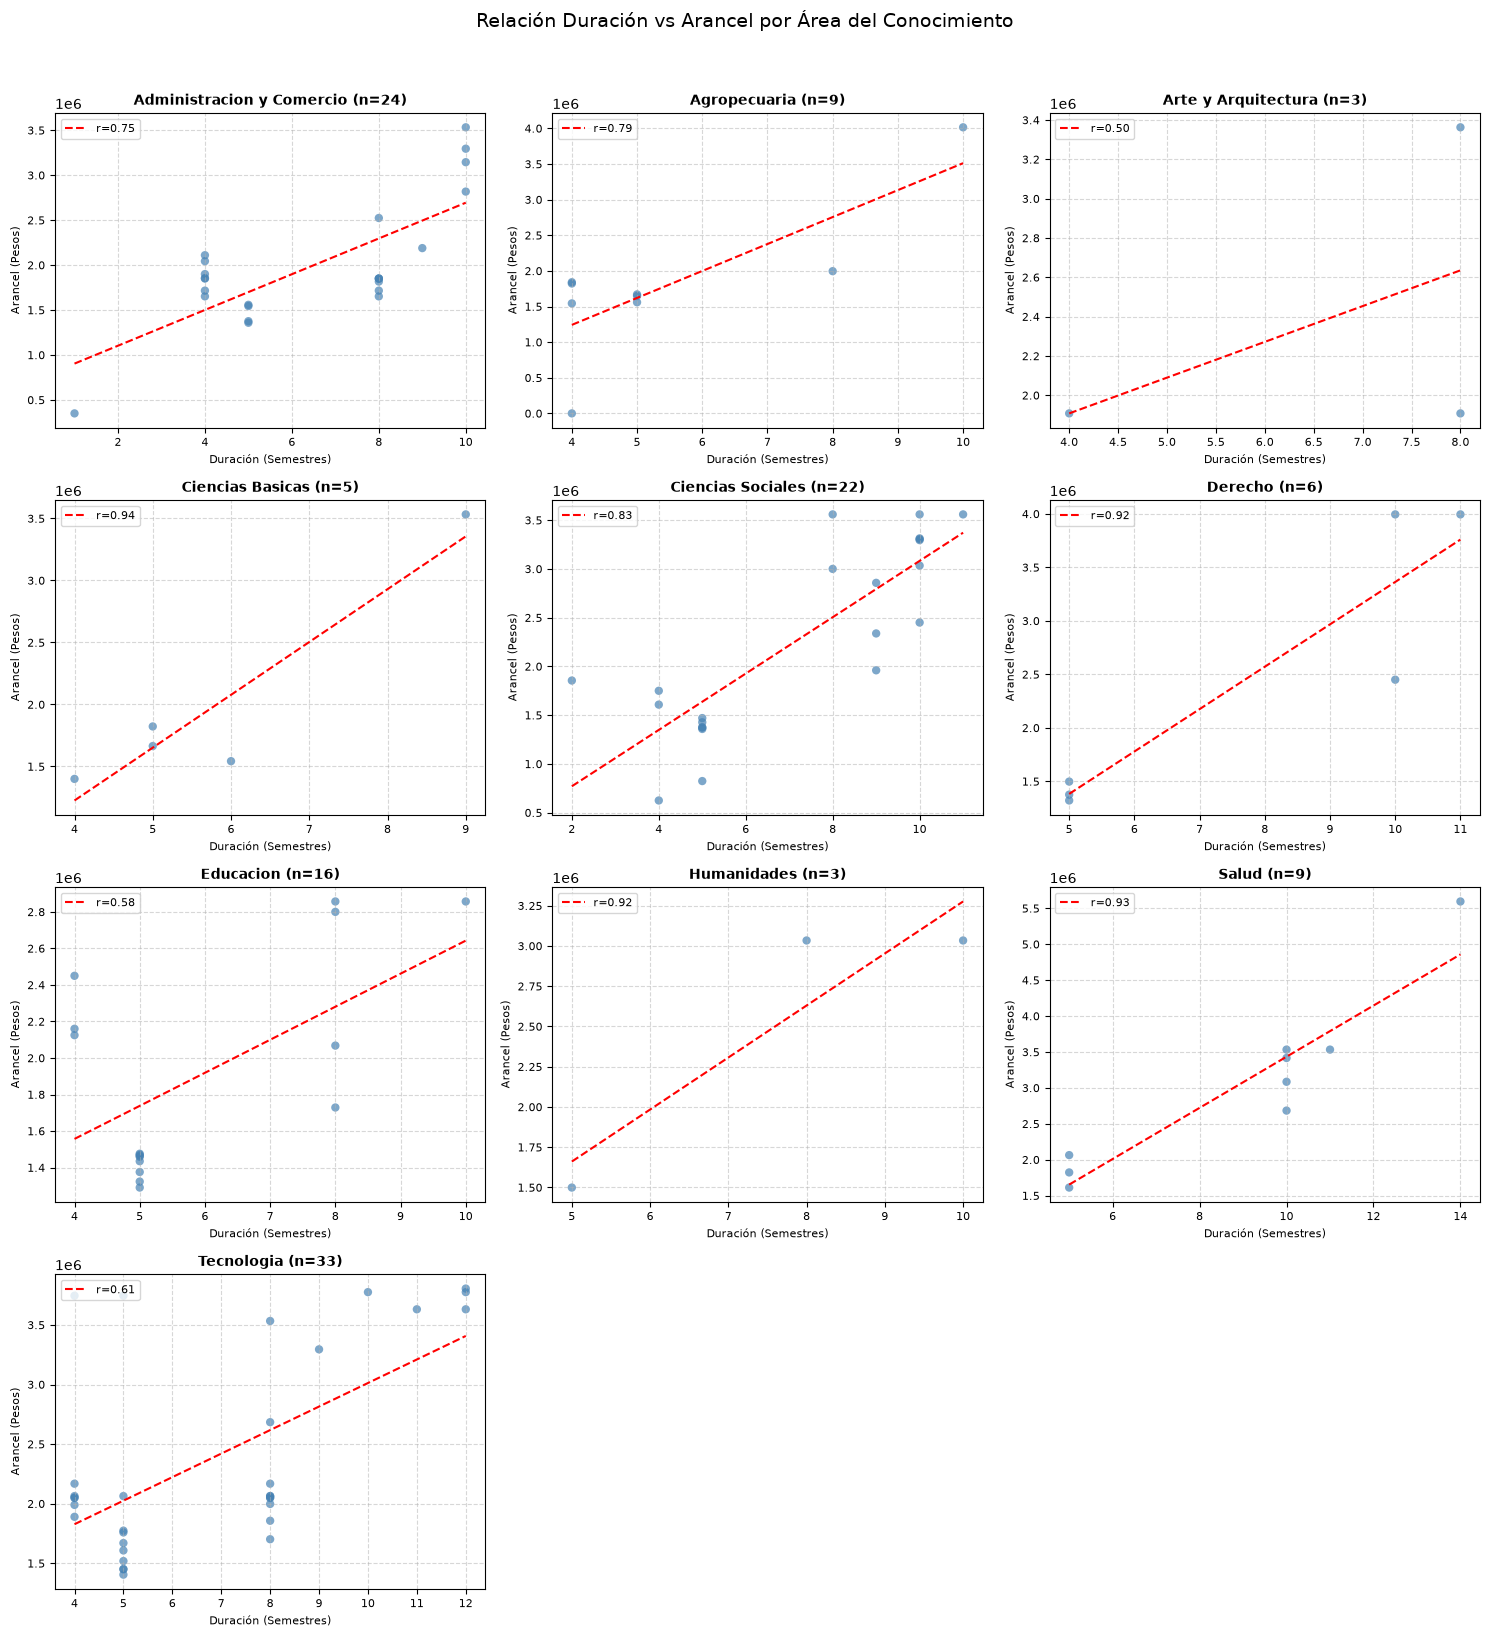

Correlación detallada por Área de Conocimiento:
- Administracion y Comercio      : r = 0.75 (n = 24)
- Agropecuaria                   : r = 0.79 (n = 9)
- Arte y Arquitectura            : r = 0.50 (n = 3)
- Ciencias Basicas               : r = 0.94 (n = 5)
- Ciencias Sociales              : r = 0.83 (n = 22)
- Derecho                        : r = 0.92 (n = 6)
- Educacion                      : r = 0.58 (n = 16)
- Humanidades                    : r = 0.92 (n = 3)
- Salud                          : r = 0.93 (n = 9)
- Tecnologia                     : r = 0.61 (n = 33)


In [8]:
# Agrupar por Área de Conocimiento usando el DataFrame de carreras únicas
grupos_area = list(carreras_unicas.groupby('AREA CONOCIMIENTO'))
num_areas = len(grupos_area)

# Determinar la grilla para los subplots (3 columnas) sin usar la librería math
cols = 3
rows = (num_areas + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows))
axes = axes.flatten()  # Aplanar para iterar fácilmente

for i, (area, group) in enumerate(grupos_area):
    ax = axes[i]
    x_group = group['DURACION TOTAL CARRERA (SEMESTRES)']
    y_group = group['VALOR ARANCEL (PESOS)']

    # Gráfico de dispersión para cada área
    ax.scatter(x_group, y_group, alpha=0.7, color='steelblue', edgecolor='none')

    # Calcular correlación y línea de tendencia con numpy
    corr = 0.0
    if len(group) > 1:
        corr = x_group.corr(y_group)
        if x_group.nunique() > 1:
            m_g, b_g = np.polyfit(x_group, y_group, 1)
            x_range = np.linspace(x_group.min(), x_group.max(), 100)
            ax.plot(x_range, m_g * x_range + b_g, color='red', linestyle='--', label=f'r={corr:.2f}')
            ax.legend(loc='upper left', fontsize=8)

    # Configuración de los ejes y títulos de cada subplot
    ax.set_title(f"{area} (n={len(group)})", fontsize=10, fontweight='bold')
    ax.set_xlabel('Duración (Semestres)', fontsize=8)
    ax.set_ylabel('Arancel (Pesos)', fontsize=8)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.tick_params(axis='both', which='major', labelsize=8)

# Ocultar los subplots vacíos que queden en la cuadrícula
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Relación Duración vs Arancel por Área del Conocimiento', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Mostrar el desglose de correlaciones por pantalla
print("Correlación detallada por Área de Conocimiento:")
for area, group in grupos_area:
    if len(group) > 1:
        corr = group['DURACION TOTAL CARRERA (SEMESTRES)'].corr(group['VALOR ARANCEL (PESOS)'])
        print(f"- {area:30} : r = {corr:.2f} (n = {len(group)})")
    else:
        print(f"- {area:30} : Insuficientes datos para calcular correlación (n = {len(group)})")

Existe una relación positiva y fuerte entre la duración de la carrera (en semestres) y su valor anual de arancel. La correlación de Pearson general entre ambas variables es de 0.77, lo que estadísticamente indica una fuerza de asociación lineal muy alta.

Sí, por lo general es verdad. Al observar la tendencia general, las carreras que duran más semestres (habitualmente carreras profesionales universitarias) concentran los aranceles más costosos, mientras que las carreras más cortas (como las carreras técnicas de 4 o 5 semestres) se ubican en los rangos de arancel más bajos.

La relación positiva se mantiene en todas las áreas, pero la intensidad de esta relación varía significativamente según el campo de estudio

# Ítem 2

### ¿Se produjo una gran vuelta a la presencialidad o los formatos que incluyen la no presencialidad han ganado terreno?

### ¿Qué tipo de institución emplea de mayor manera formatos no exclusivamente presenciales?

### ¿Cuál es la probabilidad de seleccionar de los estudiantes hombres de la región a uno del área de educación? ¿Cuál es la probabilidad de seleccionar de las estudiantes mujeres de la región a una del área de educación? ¿Hay una discrepancia aparente? ¿Cómo se explica?